# Oakland FloodWatch — starter notebook

**Goal:** find the parts of Oakland where **flood hazard** and **social vulnerability** overlap, so the city and
neighbors know where to focus drain cleaning, sandbags and flood investment.

This notebook pulls everything from free public sources (no API keys needed), builds a hexagon grid over
Oakland, and walks through:

1. Oakland boundary → H3 hex grid
2. OAK 311 flood reports (2013–today)
3. Terrain from USGS elevation (finding low spots)
4. FEMA flood zones
5. CDC Social Vulnerability Index (SVI)
6. A simple, spatially cross-validated flood-report model (+ "under-reported" hexes)
7. A combined **Flood Vulnerability Index** and interactive map
8. A check against the November 2026 storm

Every download is cached in `data/`, so re-running is fast and works offline once cached.
Cells marked **🔧 TEAM** are good places to make the project your own.

In [1]:
# If you're missing packages, uncomment:
# %pip install pandas geopandas shapely h3 requests scikit-learn osmnx matplotlib mapclassify

import json, time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import geopandas as gpd
import h3
import requests
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, shape

DATA = Path("data"); DATA.mkdir(exist_ok=True)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

H3_RES = 9           # ~0.1 km² hexes (~175 m edge). Try 8 (coarser) or 10 (finer).
CRS_M = "EPSG:26910"  # UTM zone 10N, metres — use for distances/areas
pd.set_option("display.max_columns", 50)

def get_json(url, params=None, cache=None, timeout=120):
    # GET a URL as JSON, caching the result to data/<cache> if given.
    if cache and (DATA / cache).exists():
        return json.loads((DATA / cache).read_text())
    r = requests.get(url, params=params, timeout=timeout)
    r.raise_for_status()
    js = r.json()
    if cache:
        (DATA / cache).write_text(json.dumps(js))
    return js

## 1. Oakland boundary and hex grid
The city boundary comes from the Census TIGERweb service (Oakland's place GEOID is `0653000`).

1,843 hexes at resolution 9


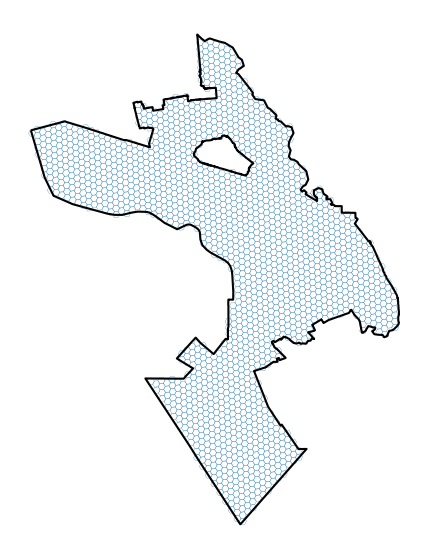

In [2]:
TIGER_PLACE = "https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/Places_CouSub_ConCity_SubMCD/MapServer/4/query"
js = get_json(TIGER_PLACE, {"where": "GEOID='0653000'", "outFields": "NAME,GEOID",
                            "outSR": 4326, "f": "geojson"}, cache="oakland_boundary.geojson")
oakland = gpd.GeoDataFrame.from_features(js["features"], crs=4326)
boundary = oakland.geometry.union_all()

cells = sorted(h3.geo_to_cells(boundary.__geo_interface__, H3_RES))
hexes = gpd.GeoDataFrame(
    {"h3": cells},
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in cells],
    crs=4326,
)
latlng = np.array([h3.cell_to_latlng(c) for c in cells])
hexes["lat"], hexes["lng"] = latlng[:, 0], latlng[:, 1]
print(f"{len(hexes):,} hexes at resolution {H3_RES}")
ax = hexes.boundary.plot(linewidth=0.2, figsize=(7, 7)); oakland.boundary.plot(ax=ax, color="k"); ax.set_axis_off()

## 2. OAK 311 flood reports
Dataset: [Service requests received by the Oakland Call Center](https://data.oaklandca.gov/) (Socrata id `quth-gb8e`).
`srx`/`sry` hold longitude/latitude.

Flood-related categories (counts as of Nov 2026): *Storm Drains – Clogged (Flooding)* ≈ 5.8k,
*Clogged (Not Flooding)* ≈ 5.6k, *Streets/Sidewalks – Pooling Water* ≈ 500, *Watershed – Overflow from a Creek* ≈ 20.

In [3]:
SOCRATA = "https://data.oaklandca.gov/resource/quth-gb8e.json"

# 🔧 TEAM: which 311 categories count as "flooding"?
FLOOD_CATS = [
    "Storm Drains - Clogged (Flooding)",
    "Streets/Sidewalks - Pooling Water",
    "Watershed - Overflow from a Creek",
]
DRAIN_CATS = [  # drain problems that weren't (yet) flooding — useful context
    "Storm Drains - Clogged (Not Flooding)",
    "Storm Inlet Grate - Damaged/Missing",
]

def fetch_311(categories, cache):
    path = DATA / cache
    if path.exists():
        return pd.read_parquet(path) if path.suffix == ".parquet" else pd.read_csv(path)
    cats = ",".join("'" + c.replace("'", "''") + "'" for c in categories)
    rows, offset = [], 0
    while True:
        batch = requests.get(SOCRATA, params={
            "$select": "requestid,datetimeinit,datetimeclosed,description,status,srx,sry,councildistrict,probaddress",
            "$where": f"description in ({cats})",
            "$order": "requestid", "$limit": 50000, "$offset": offset,
        }, timeout=120).json()
        rows += batch
        if len(batch) < 50000:
            break
        offset += 50000
    df = pd.DataFrame(rows)
    df.to_csv(path, index=False)
    return df

def clean_311(df):
    df = df.copy()
    df["lng"] = pd.to_numeric(df["srx"], errors="coerce")
    df["lat"] = pd.to_numeric(df["sry"], errors="coerce")
    df["datetimeinit"] = pd.to_datetime(df["datetimeinit"], errors="coerce")
    df["datetimeclosed"] = pd.to_datetime(df["datetimeclosed"], errors="coerce")
    minx, miny, maxx, maxy = boundary.bounds
    df = df[df.lng.between(minx, maxx) & df.lat.between(miny, maxy)]
    df["h3"] = [h3.latlng_to_cell(a, b, H3_RES) for a, b in zip(df.lat, df.lng)]
    return df[df.h3.isin(set(hexes.h3))]

flood = clean_311(fetch_311(FLOOD_CATS, "311_flood.csv"))
drain = clean_311(fetch_311(DRAIN_CATS, "311_drain.csv"))
print(f"{len(flood):,} flood reports, {len(drain):,} drain reports inside Oakland")
print("Date range:", flood.datetimeinit.min().date(), "→", flood.datetimeinit.max().date())
flood.description.value_counts()

6,166 flood reports, 6,220 drain reports inside Oakland
Date range: 2013-08-19 → 2026-11-15


description
Storm Drains - Clogged (Flooding)    5642
Streets/Sidewalks - Pooling Water     506
Watershed - Overflow from a Creek      18
Name: count, dtype: int64

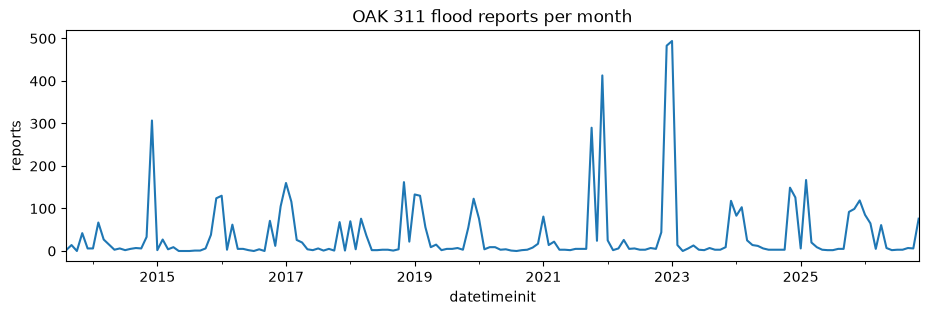

,reports
datetimeinit,
2023-01-01,494
2022-12-01,483
2021-12-01,413
2014-12-01,307
2021-10-01,290
2025-02-01,167
2018-11-01,162
2017-01-01,160


In [4]:
# When does Oakland flood? Reports per month — storm seasons and atmospheric rivers show up as spikes.
monthly = flood.set_index("datetimeinit").resample("MS").size()
ax = monthly.plot(figsize=(11, 3), title="OAK 311 flood reports per month")
ax.set_ylabel("reports"); plt.show()
monthly.sort_values(ascending=False).head(8).rename("reports").to_frame()

## 3. Terrain: elevation and local low spots
Elevation for each hex centre comes from the USGS 3DEP elevation service (lidar-based), sampled in
batches of 200 points, then cached.

`rel_elev_ft` compares a hex with its neighbours: **negative = a bowl where water collects.**

In [5]:
# USGS 3DEP ImageServer: sample many points per request (values in metres)
DEM = "https://elevation.nationalmap.gov/arcgis/rest/services/3DEPElevation/ImageServer/getSamples"
elev_cache = DATA / f"elevation_r{H3_RES}.csv"

def sample_batch(pts):
    geom = json.dumps({"points": pts, "spatialReference": {"wkid": 4326}})
    for attempt in range(4):
        try:
            r = requests.post(DEM, data={"geometry": geom, "geometryType": "esriGeometryMultipoint",
                                         "returnFirstValueOnly": "true", "f": "json"}, timeout=120)
            out = np.full(len(pts), np.nan)
            for s in r.json()["samples"]:
                try:
                    out[s["locationId"]] = float(s["value"]) * 3.28084   # metres → feet
                except (TypeError, ValueError):
                    pass   # NoData (open water)
            return out
        except Exception:
            time.sleep(2 + 2 * attempt)
    return np.full(len(pts), np.nan)

if elev_cache.exists():
    elev = pd.read_csv(elev_cache)
else:
    pts = hexes[["lng", "lat"]].values.tolist()
    batches = [pts[i:i + 200] for i in range(0, len(pts), 200)]
    with ThreadPoolExecutor(max_workers=4) as pool:
        vals = np.concatenate(list(pool.map(sample_batch, batches)))
    elev = pd.DataFrame({"h3": hexes.h3, "elev_ft": vals})
    elev.to_csv(elev_cache, index=False)

hexes = hexes.drop(columns=["elev_ft"], errors="ignore").merge(elev, on="h3", how="left")
e = hexes.set_index("h3").elev_ft.to_dict()

def neighbour_stats(c, k=2):
    vals = [e.get(n) for n in h3.grid_disk(c, k) if n != c]
    vals = [v for v in vals if v is not None and not np.isnan(v)]
    return (np.mean(vals), np.std(vals)) if vals else (np.nan, np.nan)

ns = np.array([neighbour_stats(c) for c in hexes.h3])
hexes["rel_elev_ft"] = hexes.elev_ft - ns[:, 0]   # negative = lower than surroundings
hexes["slope_proxy"] = ns[:, 1]                   # spread of neighbour elevations ≈ steepness
print(hexes[["elev_ft", "rel_elev_ft", "slope_proxy"]].describe().round(1))

       elev_ft  rel_elev_ft  slope_proxy
count   1843.0       1843.0       1843.0
mean     211.3          1.3         51.7
std      343.6         61.3         69.6
min      -30.7       -305.5          0.2
25%        0.5         -6.5          3.2
50%       26.7         -0.4         11.9
75%      265.9          3.2         85.2
max     1708.9        445.8        280.4


## 4. FEMA flood zones
From FEMA's National Flood Hazard Layer (NFHL), layer 28 = flood hazard zones.
- **SFHA** (zones A, AE, AH, AO, VE) = the official "100-year" floodplain.
- **X (0.2 PCT)** = the 500-year floodplain.

In [6]:
NFHL = "https://hazards.fema.gov/arcgis/rest/services/public/NFHL/MapServer/28/query"
minx, miny, maxx, maxy = boundary.bounds
fema_cache = DATA / "fema_nfhl_zones.geojson"
if not fema_cache.exists():
    feats, offset = [], 0
    while True:
        js = requests.get(NFHL, params={
            "geometry": f"{minx},{miny},{maxx},{maxy}", "geometryType": "esriGeometryEnvelope",
            "inSR": 4326, "outSR": 4326, "spatialRel": "esriSpatialRelIntersects",
            "outFields": "FLD_ZONE,ZONE_SUBTY,SFHA_TF", "maxAllowableOffset": 0.00002,
            "resultOffset": offset, "resultRecordCount": 1000, "f": "geojson",
        }, timeout=180).json()
        feats += js["features"]
        if len(js["features"]) < 1000:
            break
        offset += 1000
    fema_cache.write_text(json.dumps({"type": "FeatureCollection", "features": feats}))

fema = gpd.read_file(fema_cache).set_crs(4326, allow_override=True)
fema["geometry"] = fema.geometry.make_valid()
sfha = fema[fema.SFHA_TF == "T"]
x500 = fema[fema.ZONE_SUBTY.fillna("").str.contains("0.2 PCT")]
print(fema.FLD_ZONE.value_counts())

centroids = gpd.GeoDataFrame(hexes[["h3"]], geometry=gpd.points_from_xy(hexes.lng, hexes.lat), crs=4326)
hexes["in_sfha"] = centroids.within(sfha.union_all()).astype(int).values
hexes["in_500yr"] = centroids.within(x500.union_all()).astype(int).values
sfha_m = sfha.to_crs(CRS_M).union_all()
hexes["dist_sfha_m"] = centroids.to_crs(CRS_M).distance(sfha_m).values
print(f"{hexes.in_sfha.sum()} hexes in the 100-yr floodplain, {hexes.in_500yr.sum()} in the 500-yr")

FLD_ZONE
X             879
AE            271
AO            121
VE             33
A              28
AH             10
OPEN WATER      5
D               3
Name: count, dtype: int64


129 hexes in the 100-yr floodplain, 110 in the 500-yr


## 5. Social vulnerability (CDC/ATSDR SVI 2022, census tracts)
The SVI ranks every US tract from 0 (least vulnerable) to 1 (most) using 16 American Community Survey
variables. We keep the overall rank plus a few flood-relevant ones (people with no car can't evacuate easily;
limited-English households miss warnings; renters can't fix drainage themselves).

*Using SVI avoids the Census API, which now requires a free key. If you get one, you can pull any ACS variable you like.*

In [7]:
svi_path = DATA / "svi_2022_california.csv"
if not svi_path.exists():
    r = requests.get("https://svi.cdc.gov/Documents/Data/2022/csv/states/California.csv", timeout=300)
    r.raise_for_status(); svi_path.write_bytes(r.content)

SVI_COLS = {  # 🔧 TEAM: add/remove indicators
    "RPL_THEMES": "svi_overall", "EP_POV150": "pct_below_150_poverty", "EP_AGE65": "pct_65_plus",
    "EP_DISABL": "pct_disability", "EP_LIMENG": "pct_limited_english", "EP_NOVEH": "pct_no_vehicle",
    "EP_MUNIT": "pct_multiunit_housing", "E_TOTPOP": "population", "AREA_SQMI": "area_sqmi",
}
svi = pd.read_csv(svi_path, dtype={"FIPS": str}, usecols=["FIPS", *SVI_COLS])
svi["FIPS"] = svi.FIPS.str.zfill(11)
svi = svi[svi.FIPS.str.startswith("06001")].rename(columns=SVI_COLS).replace(-999, np.nan)
svi["pop_density"] = svi.population / svi.area_sqmi

TIGER_TRACTS = "https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/Tracts_Blocks/MapServer/0/query"
js = get_json(TIGER_TRACTS, {"where": "STATE='06' AND COUNTY='001'", "outFields": "GEOID",
                             "outSR": 4326, "f": "geojson"}, cache="alameda_tracts.geojson")
tracts = gpd.GeoDataFrame.from_features(js["features"], crs=4326).merge(svi, left_on="GEOID", right_on="FIPS")

joined = gpd.sjoin(centroids, tracts.drop(columns=["FIPS"]), how="left", predicate="within")
joined = joined[~joined.index.duplicated()]
for col in ["GEOID", *SVI_COLS.values(), "pop_density"]:
    hexes[col] = joined[col].values

# Drop hexes that are open water / have no residents data
hexes = hexes[hexes.elev_ft.notna() & hexes.GEOID.notna()].reset_index(drop=True)
print(f"{len(hexes):,} land hexes with tract data")

1,448 land hexes with tract data


## 6. Model: where *should* we expect flood reports?
Target = did this hex ever get a 311 flood report? Features = terrain, FEMA zones and population density
(more people → more reports, so we control for it).

We use **spatial cross-validation**: hexes are grouped into larger parent cells so the model is always
tested on neighbourhoods it hasn't seen (otherwise neighbouring hexes leak answers and accuracy looks too good).

The interesting output is the **gap**: hexes the model rates as flood-prone but which have *no* reports.
These may be **under-reported**, often in areas where residents are less likely to use 311.

In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

counts = flood.groupby("h3").size().rename("flood_reports")
dcounts = drain.groupby("h3").size().rename("drain_reports")
hexes = hexes.drop(columns=["flood_reports", "drain_reports"], errors="ignore") \
             .merge(counts, on="h3", how="left").merge(dcounts, on="h3", how="left")
hexes[["flood_reports", "drain_reports"]] = hexes[["flood_reports", "drain_reports"]].fillna(0)
hexes["y"] = (hexes.flood_reports > 0).astype(int)

FEATURES = ["elev_ft", "rel_elev_ft", "slope_proxy", "in_sfha", "in_500yr", "dist_sfha_m", "pop_density"]
X, y = hexes[FEATURES], hexes.y
groups = [h3.cell_to_parent(c, 6) for c in hexes.h3]   # ~36 km² blocks for spatial CV

oof = np.zeros(len(hexes))
for train, test in GroupKFold(n_splits=5).split(X, y, groups):
    m = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=0)
    m.fit(X.iloc[train], y.iloc[train])
    oof[test] = m.predict_proba(X.iloc[test])[:, 1]

hexes["p_flood"] = oof
print(f"Share of hexes with ≥1 flood report: {y.mean():.0%}")
print(f"Spatial-CV ROC AUC: {roc_auc_score(y, oof):.3f}   PR AUC: {average_precision_score(y, oof):.3f} "
      f"(baseline {y.mean():.3f})")

Share of hexes with ≥1 flood report: 58%
Spatial-CV ROC AUC: 0.837   PR AUC: 0.847 (baseline 0.578)


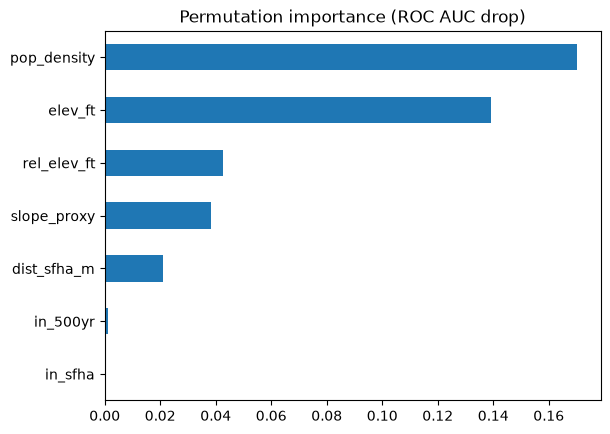

48 possibly under-reported hexes


,svi_overall,pct_limited_english,pct_below_150_poverty
maybe_underreported,,,
0,0.42,5.50,16.53
1,0.47,7.38,18.41


In [9]:
# Which features matter? (permutation importance on a model fit to everything)
from sklearn.inspection import permutation_importance
full = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=0).fit(X, y)
pi = permutation_importance(full, X, y, scoring="roc_auc", n_repeats=10, random_state=0)
pd.Series(pi.importances_mean, index=FEATURES).sort_values().plot.barh(title="Permutation importance (ROC AUC drop)")
plt.show()

# Possibly under-reported: model says top-25% risk, but zero flood reports ever.
thresh = hexes.p_flood.quantile(0.75)
hexes["maybe_underreported"] = ((hexes.p_flood >= thresh) & (hexes.flood_reports == 0)).astype(int)
print(f"{hexes.maybe_underreported.sum()} possibly under-reported hexes")
hexes.groupby("maybe_underreported")[["svi_overall", "pct_limited_english", "pct_below_150_poverty"]].mean().round(2)

## 7. Flood Vulnerability Index
**Hazard** blends three signals (each converted to a 0–1 percentile):
the model's predicted risk, actual report history, and FEMA zone.
**Vulnerability** is the CDC SVI rank. The final index is their weighted geometric mean, so a hex must
score high on *both* to rank at the top.

🔧 **TEAM:** these weights are judgment calls. Show judges how the ranking shifts when you change them.

In [10]:
W_HAZARD = {"model": 0.4, "reports": 0.3, "fema": 0.3}
W_INDEX = {"hazard": 0.5, "vulnerability": 0.5}

pct = lambda s: s.rank(pct=True)
hexes["fema_score"] = np.select([hexes.in_sfha == 1, hexes.in_500yr == 1], [1.0, 0.5], 0.0)
hexes["hazard"] = (W_HAZARD["model"] * pct(hexes.p_flood)
                   + W_HAZARD["reports"] * pct(hexes.flood_reports + 0.5 * hexes.drain_reports)
                   + W_HAZARD["fema"] * hexes.fema_score)
hexes["hazard"] = pct(hexes.hazard)
hexes["vulnerability"] = hexes.svi_overall.fillna(hexes.svi_overall.median())
hexes["fvi"] = (hexes.hazard ** W_INDEX["hazard"]) * (hexes.vulnerability ** W_INDEX["vulnerability"])

def why(r):
    reasons = []
    if r.in_sfha: reasons.append("FEMA 100-yr floodplain")
    elif r.in_500yr: reasons.append("FEMA 500-yr floodplain")
    if r.rel_elev_ft < -3: reasons.append(f"low spot ({-r.rel_elev_ft:.0f} ft below the surrounding area)")
    if r.flood_reports: reasons.append(f"{int(r.flood_reports)} flood reports")
    if r.maybe_underreported: reasons.append("likely under-reported")
    if r.pct_no_vehicle >= 20: reasons.append(f"{r.pct_no_vehicle:.0f}% no car")
    if r.pct_limited_english >= 10: reasons.append(f"{r.pct_limited_english:.0f}% limited English")
    if r.svi_overall >= 0.8: reasons.append(f"SVI {r.svi_overall:.2f}")
    return "; ".join(reasons)

hexes["why"] = hexes.apply(why, axis=1)
top = hexes.sort_values("fvi", ascending=False).head(15)
top[["h3", "fvi", "hazard", "vulnerability", "flood_reports", "elev_ft", "why"]].round(2)

,h3,fvi,hazard,vulnerability,flood_reports,elev_ft,why
1004,89283098b83ffff,0.99,1.00,0.99,18.0,53.92,FEMA 500-yr floodplain; 18 flood reports; 28% ...
1078,89283098e53ffff,0.98,0.98,0.99,3.0,21.83,FEMA 500-yr floodplain; 3 flood reports; SVI 0.99
1079,89283098e57ffff,0.98,0.97,0.99,4.0,12.27,FEMA 500-yr floodplain; low spot (9 ft below t...
824,89283098327ffff,0.98,0.97,0.99,2.0,26.11,FEMA 500-yr floodplain; 2 flood reports; SVI 0.99
955,89283098a83ffff,0.97,0.97,0.98,18.0,48.74,low spot (9 ft below the surrounding area); 18...
1010,89283098b9bffff,0.97,1.00,0.94,16.0,53.81,FEMA 500-yr floodplain; 16 flood reports; 20% ...
961,89283098a9bffff,0.97,0.95,0.98,11.0,44.56,low spot (8 ft below the surrounding area); 11...
896,89283098863ffff,0.96,0.99,0.94,3.0,36.68,FEMA 500-yr floodplain; low spot (5 ft below t...
899,8928309886fffff,0.96,0.98,0.94,2.0,47.71,FEMA 500-yr floodplain; low spot (9 ft below t...
1060,89283098e03ffff,0.96,1.00,0.92,33.0,10.49,FEMA 500-yr floodplain; low spot (4 ft below t...


In [11]:
# Roll up to census tracts — easier to talk about than hexes
by_tract = (hexes.groupby("GEOID")
            .agg(mean_fvi=("fvi", "mean"), max_fvi=("fvi", "max"), flood_reports=("flood_reports", "sum"),
                 hexes_in_sfha=("in_sfha", "sum"), svi=("svi_overall", "first"),
                 population=("population", "first"))
            .sort_values("mean_fvi", ascending=False))
by_tract.head(10).round(2)

,mean_fvi,max_fvi,flood_reports,hexes_in_sfha,svi,population
GEOID,,,,,,
06001406202,0.95,0.99,26.0,0,0.99,4733.0
06001407200,0.94,0.97,38.0,0,0.94,6544.0
06001408900,0.93,0.98,32.0,0,0.99,3956.0
06001408800,0.93,0.96,166.0,0,0.92,7968.0
06001407500,0.92,0.97,36.0,0,0.98,3988.0
06001407400,0.92,0.96,15.0,0,0.92,4242.0
06001406201,0.92,0.95,38.0,0,0.94,5072.0
06001408400,0.91,0.94,48.0,0,0.90,4077.0
06001408500,0.91,0.93,60.0,0,0.87,5634.0


## 8. Map

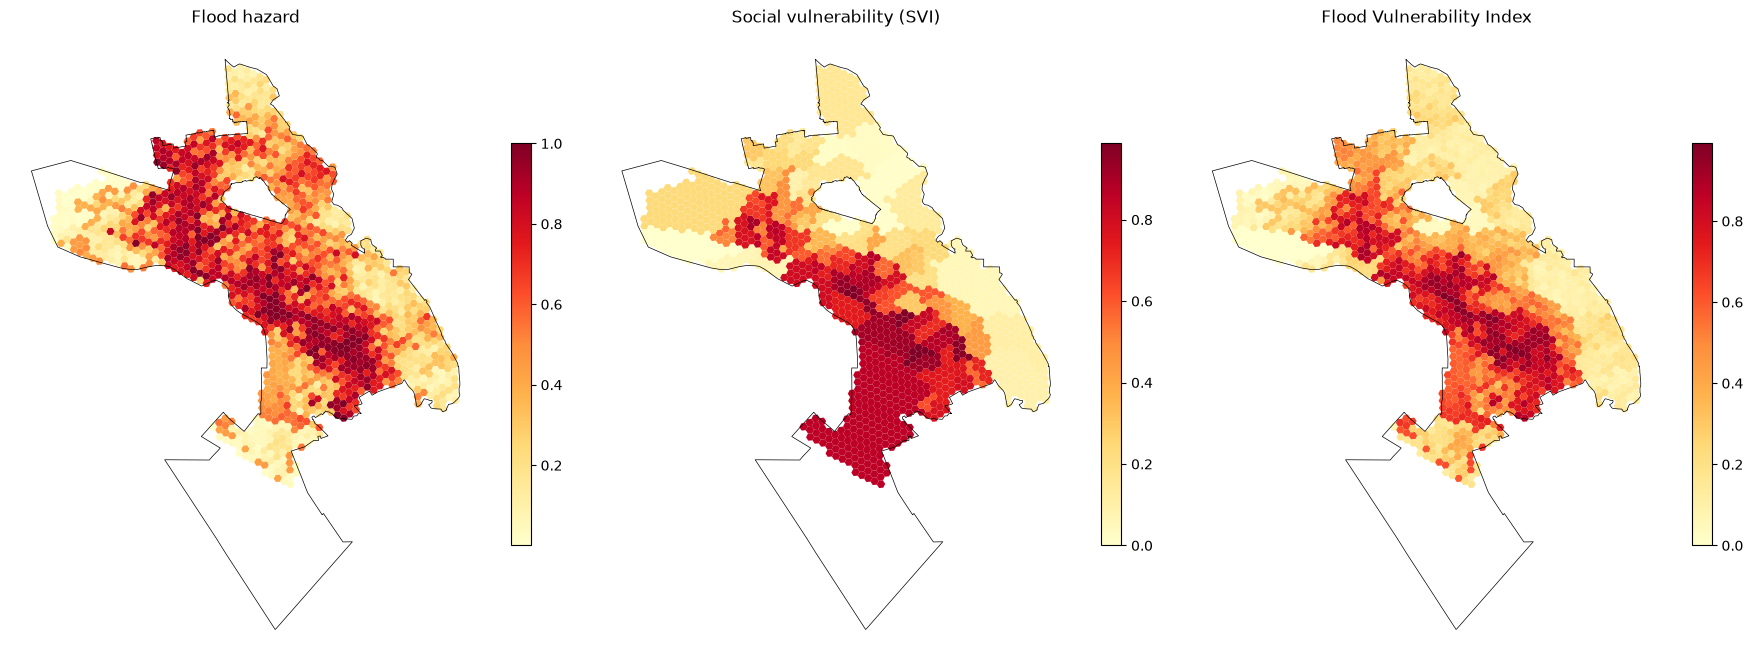

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, col, title in zip(axes, ["hazard", "vulnerability", "fvi"],
                          ["Flood hazard", "Social vulnerability (SVI)", "Flood Vulnerability Index"]):
    hexes.plot(column=col, cmap="YlOrRd", ax=ax, legend=True, legend_kwds={"shrink": 0.6})
    oakland.boundary.plot(ax=ax, color="k", linewidth=0.5)
    ax.set_title(title); ax.set_axis_off()
plt.tight_layout(); plt.savefig(OUT / "fvi_maps.png", dpi=150); plt.show()

### Key infrastructure
Places where a flood does the most harm, from official sources (the same ones the team pipeline uses):
Oakland Fire Department stations, state-licensed hospitals, nursing homes and dialysis clinics (CDPH),
large public schools (California Dept. of Education, 2024–25; 500+ students, 25 of Oakland's 118) and BART
stations. Each is matched to the hex it sits in.

In [13]:
import string
OAK_BOX = dict(geometry="{},{},{},{}".format(*boundary.bounds), geometryType="esriGeometryEnvelope", inSR=4326,
               spatialRel="esriSpatialRelIntersects", outFields="*", outSR=4326, f="geojson")
FAC_SOURCES = {
    "fire": "https://services.arcgis.com/9tC74aDHuml0x5Yz/arcgis/rest/services/OFD_Basemap/FeatureServer/5",
    "cdph": "https://services5.arcgis.com/FlidZxdI0LGC9vAw/arcgis/rest/services/CDPH_LC_Facilities_Data/FeatureServer/0",
    "schools": "https://services3.arcgis.com/fdvHcZVgB2QSRNkL/arcgis/rest/services/SchoolSites2425/FeatureServer/0",
    "bart": "https://services.arcgis.com/9tC74aDHuml0x5Yz/arcgis/rest/services/Bart_Stations/FeatureServer/0",
}

def arcgis_points(name):
    path = DATA / f"fac_{name}.geojson"
    if not path.exists():
        feats, offset = [], 0
        while True:
            page = requests.get(FAC_SOURCES[name] + "/query", params=dict(OAK_BOX, resultOffset=offset), timeout=120).json()
            feats += page["features"]
            if not (page.get("properties", {}).get("exceededTransferLimit") or page.get("exceededTransferLimit")):
                break
            offset += len(page["features"])
        path.write_text(json.dumps({"type": "FeatureCollection", "features": feats}))
    g = gpd.read_file(path)
    return g[g.geometry.notna() & ~g.geometry.is_empty]

def col(g, *names):
    for n in names:
        if n in g.columns:
            return g[n].fillna("").astype(str).str.strip()
    return pd.Series("", index=g.index)

parts = []
g = arcgis_points("fire")
parts.append(gpd.GeoDataFrame(dict(ftype="fire_station", name="Fire Station " + col(g, "STATION"),
                                   address=col(g, "ADDRESS"), detail=""), geometry=g.geometry, crs=4326))
g = arcgis_points("cdph")
g = g[col(g, "LICENSE_STATUS_DESCRIPTION").str.upper().str.contains("ACTIVE") | col(g, "FAC_STATUS_TYPE_CODE").str.upper().eq("OPEN")]
kind = col(g, "FAC_FDR").str.upper()
for ftype, mask in [("hospital", kind.eq("GENERAL ACUTE CARE HOSPITAL")),
                    ("nursing_home", kind.eq("SKILLED NURSING FACILITY")),
                    ("dialysis", kind.eq("CHRONIC DIALYSIS CLINIC"))]:
    s = g[mask]
    parts.append(gpd.GeoDataFrame(dict(ftype=ftype, name=col(s, "FACNAME").map(string.capwords),
                                       address=col(s, "ADDRESS").map(string.capwords), detail=""), geometry=s.geometry, crs=4326))
MIN_SCHOOL_ENROLLMENT = 500   # 🔧 TEAM: only larger schools (25 of 118 at 500+); lower it to show more
g = arcgis_points("schools")
g = g[col(g, "Status").replace("", "Active").eq("Active")]
g = g[pd.to_numeric(g.get("EnrollTotal"), errors="coerce").fillna(0) >= MIN_SCHOOL_ENROLLMENT]
enroll = pd.to_numeric(g.get("EnrollTotal"), errors="coerce")
parts.append(gpd.GeoDataFrame(dict(ftype="school", name=col(g, "SchoolName"), address=col(g, "Street"),
                                   detail=[f"{int(e):,} students enrolled" if pd.notna(e) and e > 0 else "" for e in enroll]),
                              geometry=g.geometry, crs=4326))
g = arcgis_points("bart")
parts.append(gpd.GeoDataFrame(dict(ftype="bart", name=col(g, "NAME_LONG", "NAME"), address=col(g, "ADDRESS"), detail=""),
                              geometry=g.geometry, crs=4326))

fac = pd.concat(parts, ignore_index=True)
fac = fac[fac.geometry.within(boundary)].drop_duplicates(["ftype", "name"]).reset_index(drop=True)
fac["h3"] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in fac.geometry]

# Community services from the team pipeline (pipeline/11_services.py -> outputs/facilities.geojson): libraries,
# senior centers, rec centers & pools, Head Start (City of Oakland open data, 2013). Shown as map markers only;
# they don't change the risk score. The file's website_type == true rows duplicate the markers built above.
svc_path = OUT / "facilities.geojson"
if svc_path.exists():
    cs = gpd.read_file(svc_path)
    cs = cs[~cs.website_type.astype(bool)].copy()
    imp5 = [v[5] if isinstance(v, (list, tuple)) and len(v) == 6 and v[5] is not None else None for v in cs.streets_impassable]
    community = gpd.GeoDataFrame(dict(
        ftype=cs.ftype, name=cs.name, address=cs.address.fillna(""), detail=cs.detail.fillna(""),
        rep250=cs.flood_reports_250m, in_study=cs.in_study_area.astype(bool), site_flood_ft=cs.site_flood_ft,
        access_loss_ft=cs.access_loss_ft, imp5=imp5), geometry=cs.geometry, crs=4326)
    community["h3"] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in community.geometry]
    fac = pd.concat([fac, community], ignore_index=True)
print(fac.ftype.value_counts().to_string())

ftype
rec_center       28
fire_station     26
school           25
nursing_home     18
library          18
head_start       17
dialysis         11
bart              8
senior_center     8
hospital          5


### Roads and daily services
Flooding that blocks a main road, a bus line or the only grocery store nearby disrupts daily life even when no
home floods. From OpenStreetMap (citywide, cached in `data/`):
- **Major roads**: freeways, highways, arterials and collectors (`motorway` to `tertiary`). Bridges and tunnels are
  left out, since street flooding doesn't block them.
- **Bus stops**: many residents without a car depend on them.
- **Major grocery stores and pharmacies**: everyday needs. Only major grocery stores count (supermarket chains
  such as Safeway, Lucky, FoodMaxx and Grocery Outlet, or any supermarket with a footprint of 1,500 m² or more),
  since those are where most residents shop; small corner markets and produce stands are left out.

In [14]:
import tempfile
import osmnx as ox
ox.settings.use_cache = True
ox.settings.cache_folder = str(Path(tempfile.gettempdir()) / "floodwatch_osm_cache")  # short path (Windows)
ox.settings.http_user_agent = "floodwatch-notebook/0.1"
ox.settings.log_console = False

def osm_layer(name, tags):
    path = DATA / f"osm_{name}.geojson"
    if not path.exists():
        g = ox.features_from_bbox(boundary.bounds, tags=tags)   # bbox query; clipped to Oakland below
        g = g[g.geometry.intersects(boundary)].reset_index()
        keep = [c for c in ["highway", "name", "ref", "bridge", "tunnel", "shop", "amenity"] if c in g.columns]
        g = g[keep + ["geometry"]].copy()
        for c in keep:
            g[c] = g[c].apply(lambda v: ";".join(map(str, v)) if isinstance(v, list) else v)
        g.to_file(path, driver="GeoJSON")
    return gpd.read_file(path)

ROAD_CLASSES = ["motorway", "trunk", "primary", "secondary", "tertiary",
                "motorway_link", "trunk_link", "primary_link", "secondary_link"]
roads = osm_layer("roads", {"highway": ROAD_CLASSES})
bus = osm_layer("bus_stops", {"highway": "bus_stop"})
daily = osm_layer("daily", {"shop": ["supermarket", "grocery", "greengrocer"], "amenity": "pharmacy"})

# 🔧 TEAM: "major" grocery stores only: supermarket chains, or any supermarket with a large footprint
MAJOR_GROCERY_CHAINS = ["safeway", "lucky", "foodmaxx", "foods co", "grocery outlet", "smart & final", "sprouts",
                        "whole foods", "trader joe", "cardenas", "target"]
MIN_GROCERY_M2 = 1500
is_pharmacy = daily.get("amenity").eq("pharmacy")
grocery_name = daily.get("name").fillna("").str.lower()
footprint = daily.to_crs(CRS_M).area
is_major_grocery = daily.get("shop").eq("supermarket") & (
    grocery_name.apply(lambda s: any(c in s for c in MAJOR_GROCERY_CHAINS)) | (footprint >= MIN_GROCERY_M2))
print(f"Grocery places in OSM: {int((~is_pharmacy).sum())}; kept as major grocery stores: {int(is_major_grocery.sum())}")
daily = daily[is_pharmacy | is_major_grocery].copy()

roads = roads[roads.geometry.geom_type.isin(["LineString", "MultiLineString"])]
on_structure = roads.get("bridge", pd.Series(index=roads.index)).fillna("no").ne("no") | \
               roads.get("tunnel", pd.Series(index=roads.index)).fillna("no").ne("no")
roads = roads[~on_structure].copy()
print(f"{len(roads):,} major road segments (excluding bridges/tunnels), {len(bus):,} bus stops, "
      f"{int((daily.get('amenity') != 'pharmacy').sum())} major grocery stores, "
      f"{int((daily.get('amenity') == 'pharmacy').sum())} pharmacies")
roads.highway.value_counts()

Grocery places in OSM: 87; kept as major grocery stores: 24
6,114 major road segments (excluding bridges/tunnels), 1,683 bus stops, 24 major grocery stores, 25 pharmacies


highway
secondary         2582
tertiary          1357
primary           1120
motorway_link      510
motorway           370
secondary_link     104
primary_link        69
trunk                2
Name: count, dtype: int64

### Overall risk: adding daily-life disruption
The map's **overall risk** keeps the FVI's logic (likely to flood × serious consequences) but widens
"consequences" from *who lives here* to *what a flood would disrupt*:

| Part | What it measures | How |
|---|---|---|
| **Key facilities** | Hospitals, nursing homes, dialysis clinics, fire stations, BART, large schools | Weighted by harm (hospital 3; nursing home, dialysis, fire station 2; BART, large school 1.5); sites in the hex plus half of those in the six touching hexes (~300 m); score `1 − exp(−w / 3)` |
| **Roads** | Important roads a flood could block | Road length inside the hex × importance (freeway/highway 3, arterial 2.5, secondary 2, collector 1, ramps 1); score `1 − exp(−w / R)`, where R makes a typical road-carrying hex score 0.5 |
| **Daily services** | Bus stops, grocery stores, pharmacies | Bus stop 0.3, grocery/pharmacy 1.5, hex plus half of touching hexes; same 0–1 scaling |

- **Disruption** = 40% key facilities + 35% roads + 25% daily services.
- **Impact** = 60% social vulnerability + 40% disruption.
- **Overall risk** = √(hazard × impact): high only where flooding is likely *and* it would hurt people and daily life.
  This is the ranking to use for **where to put drains, cleanups and flood help first**.

The people-only FVI from section 7 is kept (`fvi`) for comparison; the backtest in section 9 is unaffected.

🔧 **TEAM:** all weights below are judgment calls; change them and re-run.

In [15]:
FAC_WEIGHT = {"hospital": 3, "nursing_home": 2, "dialysis": 2, "fire_station": 2, "bart": 1.5, "school": 1.5}
ROAD_WEIGHT = {"motorway": 3, "trunk": 3, "primary": 2.5, "secondary": 2, "tertiary": 1,
               "motorway_link": 1, "trunk_link": 1, "primary_link": 1, "secondary_link": 1}
SERVICE_WEIGHT = {"bus_stop": 0.3, "grocery": 1.5, "pharmacy": 1.5}
NEIGHBOR_SHARE = 0.5                                   # things in touching hexes count half
DISRUPTION_W = {"facilities": 0.40, "roads": 0.35, "services": 0.25}
IMPACT_W = {"vulnerability": 0.60, "disruption": 0.40}

ring = {c: [n for n in h3.grid_disk(c, 1) if n != c] for c in hexes.h3}
def cluster(weights_by_hex):
    return np.array([weights_by_hex.get(c, 0) + NEIGHBOR_SHARE * sum(weights_by_hex.get(n, 0) for n in ring[c])
                     for c in hexes.h3])
def scaled(w, k):
    return 1 - np.exp(-np.asarray(w) / k)
def half_at_median(w):                                 # k so the median non-zero hex scores 0.5
    nz = np.asarray(w)[np.asarray(w) > 0]
    return np.median(nz) / np.log(2)

# --- key facilities
key = fac[fac.ftype.isin(FAC_WEIGHT)].copy()          # community services are markers only, not scored
key["weight"] = key.ftype.map(FAC_WEIGHT)
here_n = key.groupby("h3").size()
hexes["fac_nearby"] = [int(here_n.get(c, 0) + sum(here_n.get(n, 0) for n in ring[c])) for c in hexes.h3]
hexes["infrastructure"] = scaled(cluster(key.groupby("h3").weight.sum().to_dict()), 3)

# --- roads: clip to hexes in metres, length x importance
hex_m = hexes[["h3", "geometry"]].to_crs(CRS_M)
rd = roads[["highway", "name", "ref", "geometry"]].to_crs(CRS_M)
rd["highway"] = rd.highway.str.split(";").str[0]
rd = gpd.overlay(rd, hex_m, how="intersection", keep_geom_type=True)
rd["km"] = rd.length / 1000
rd["w"] = rd.km * rd.highway.map(ROAD_WEIGHT).fillna(1)
rd["label"] = rd.name.fillna(rd.ref).fillna("")
road_w = rd.groupby("h3").w.sum()
hexes["road_km"] = hexes.h3.map(rd.groupby("h3").km.sum()).fillna(0).round(2)
hexes["road_w"] = hexes.h3.map(road_w).fillna(0)
R = half_at_median(hexes.road_w)
hexes["roads_score"] = scaled(hexes.road_w, R)
top_names = (rd[rd.label != ""].groupby(["h3", "label"]).w.sum().reset_index()
             .sort_values("w", ascending=False).groupby("h3").label.apply(lambda s: list(s)[:3]))
hexes["road_names"] = hexes.h3.map(top_names).apply(lambda v: v if isinstance(v, list) else [])

# --- daily services: bus stops, groceries, pharmacies
pts = lambda g: g.geometry.representative_point() if not g.empty else g.geometry
svc = pd.concat([
    pd.DataFrame({"kind": "bus_stop", "name": bus.get("name"), "geom": list(pts(bus))}),
    pd.DataFrame({"kind": np.where(daily.get("amenity").eq("pharmacy"), "pharmacy", "grocery"),
                  "name": daily.get("name"), "geom": list(pts(daily))}),
], ignore_index=True)
svc["h3"] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in svc.geom]
svc["w"] = svc.kind.map(SERVICE_WEIGHT)
svc_w = cluster(svc.groupby("h3").w.sum().to_dict())
K = half_at_median(svc_w)
hexes["services_score"] = scaled(svc_w, K)
cnt = lambda kind: svc[svc.kind == kind].groupby("h3").size()
near = lambda s: [int(s.get(c, 0) + sum(s.get(n, 0) for n in ring[c])) for c in hexes.h3]
hexes["bus_stops_nearby"] = near(cnt("bus_stop"))
hexes["groceries_nearby"] = near(cnt("grocery"))
hexes["pharmacies_nearby"] = near(cnt("pharmacy"))

# --- combine
hexes["disruption"] = (DISRUPTION_W["facilities"] * hexes.infrastructure + DISRUPTION_W["roads"] * hexes.roads_score
                       + DISRUPTION_W["services"] * hexes.services_score)
hexes["impact"] = IMPACT_W["vulnerability"] * hexes.vulnerability + IMPACT_W["disruption"] * hexes.disruption
hexes["overall"] = np.sqrt(hexes.hazard * hexes.impact)
hexes["fvi_base"] = hexes.fvi   # explicit name for the people-only score (flood x vulnerability, no disruption)

# plain-English reasons
def extra_why(r):
    out = []
    if r.fac_nearby >= 3: out.append(f"{r.fac_nearby} key facilities within ~300 m")
    if r.roads_score >= 0.7 and r.road_names: out.append("major road: " + ", ".join(r.road_names[:2]))
    if r.bus_stops_nearby >= 8: out.append(f"{r.bus_stops_nearby} bus stops nearby")
    return out
hexes["why"] = ["; ".join([w] * bool(w) + extra_why(r)) for w, r in zip(hexes.why, hexes.itertuples())]

print(f"Road scale R = {R:.2f} weighted km; services scale K = {K:.2f}")
print(f"Hexes with a major road: {(hexes.road_km > 0).mean():.0%}; with a key facility within ~300 m: "
      f"{(hexes.fac_nearby > 0).mean():.0%}; with a bus stop within ~300 m: {(hexes.bus_stops_nearby > 0).mean():.0%}")
print(f"Rank correlation, people-only FVI vs overall risk: {hexes.fvi.corr(hexes.overall, method='spearman'):.2f}")
moved = hexes.assign(change=(hexes.overall.rank(pct=True) - hexes.fvi.rank(pct=True)) * 100)
moved.sort_values("change", ascending=False).head(8)[
    ["h3", "road_km", "bus_stops_nearby", "fac_nearby", "fvi", "overall", "change", "why"]].round(2)

Road scale R = 1.31 weighted km; services scale K = 2.81
Hexes with a major road: 63%; with a key facility within ~300 m: 28%; with a bus stop within ~300 m: 70%
Rank correlation, people-only FVI vs overall risk: 0.95


,h3,road_km,bus_stops_nearby,fac_nearby,fvi,overall,change,why
512,8928308a467ffff,2.40,15,0,0.05,0.36,45.10,"6 flood reports; major road: Warren Freeway, L..."
192,892830812d3ffff,0.61,20,0,0.04,0.36,44.89,low spot (62 ft below the surrounding area); 4...
438,8928308a153ffff,2.05,12,1,0.10,0.45,44.75,low spot (137 ft below the surrounding area); ...
402,8928308a083ffff,1.66,15,1,0.04,0.34,41.51,low spot (90 ft below the surrounding area); 3...
414,8928308a0bbffff,2.74,12,1,0.04,0.33,41.16,low spot (154 ft below the surrounding area); ...
388,8928308a037ffff,1.33,16,0,0.08,0.36,39.02,low spot (106 ft below the surrounding area); ...
548,8928308a543ffff,0.67,18,0,0.05,0.32,38.60,low spot (53 ft below the surrounding area); 9...
270,89283081563ffff,0.70,14,1,0.00,0.27,37.64,FEMA 500-yr floodplain; low spot (5 ft below t...


### Future flooding: sea-level rise across all of Oakland
The team's pipeline maps sea-level rise for West Oakland in detail. For the whole city we use the **same official
source**: the ART Bay Shoreline Flood Explorer (BCDC), rendered at 5 m for +1 to +5 ft above today's high tide
(5 ft uses ART's 66-inch map, the team's conservative choice). For each hex we record the share of land that floods
(water connected to the Bay) and the share that is **low-lying**: below the water level but behind higher ground,
where groundwater and backed-up drains cause flooding first.

When could this happen? State of California guidance (Ocean Protection Council 2024, statewide values):
about **0.8–1.0 ft by 2050** and **3.1 ft (Intermediate) to 4.9 ft (Intermediate-High) by 2100**. Storms come on
top: a 1-in-100-year storm tide today is about 2.8 ft above normal high tide, so **today's 100-year storm
temporarily floods roughly what the +3 ft map shows**.

For buildings in the team's West Oakland study area, the map also uses the pipeline's building-level results
(from the committed building export files, pipeline step 08): whether each building floods, how deep, whether it gets cut off from
emergency services, and whether it ends up near a contaminated site.

In [16]:
from rasterio.features import rasterize
from rasterio.transform import from_origin
from PIL import Image
import io, glob

ART_WMS = "https://mapserver.adaptingtorisingtides.org/cgi-bin/mapserv?map=/opt/slrviewer/mapfiles/bcdc.map"
SLR_LEVELS_IN = {1: 12, 2: 24, 3: 36, 4: 48, 5: 66}       # ft above today's high tide -> ART map (inches)
ART_RES, TILE = 5, 2048                                    # metres per pixel, pixels per WMS request
SLR_YEARS = {1: "around 2050", 2: "between 2050 and 2100", 3: "by 2100 (Intermediate scenario)",
             4: "by 2100 (between Intermediate and Intermediate-High)", 5: "by 2100 (Intermediate-High or higher)"}

bx0, by0, bx1, by1 = gpd.GeoSeries([boundary], crs=4326).to_crs(CRS_M).total_bounds
bx0, by0 = np.floor(bx0 / ART_RES) * ART_RES, np.floor(by0 / ART_RES) * ART_RES
bx1, by1 = np.ceil(bx1 / ART_RES) * ART_RES, np.ceil(by1 / ART_RES) * ART_RES
W, Hh = int((bx1 - bx0) / ART_RES), int((by1 - by0) / ART_RES)
T5 = from_origin(bx0, by1, ART_RES, ART_RES)
(DATA / "art").mkdir(exist_ok=True)

def art_layer(layer):
    out = np.zeros((Hh, W), bool)
    for ty in range(int(np.ceil(Hh / TILE))):
        for tx in range(int(np.ceil(W / TILE))):
            w, h = min(TILE, W - tx * TILE), min(TILE, Hh - ty * TILE)
            x0, y1 = bx0 + tx * TILE * ART_RES, by1 - ty * TILE * ART_RES
            f = DATA / "art" / f"{layer}_{ty}_{tx}.png"
            if not f.exists():
                r = requests.get(ART_WMS, timeout=180, params=dict(
                    SERVICE="WMS", VERSION="1.3.0", REQUEST="GetMap", LAYERS=layer, STYLES="", CRS="EPSG:26910",
                    BBOX=f"{x0},{y1 - h * ART_RES},{x0 + w * ART_RES},{y1}", WIDTH=w, HEIGHT=h,
                    FORMAT="image/png", TRANSPARENT="TRUE"))
                r.raise_for_status()
                assert r.headers.get("content-type", "").startswith("image"), r.text[:300]
                f.write_bytes(r.content); time.sleep(0.2)
            a = np.array(Image.open(f).convert("RGBA"))
            out[ty * TILE: ty * TILE + h, tx * TILE: tx * TILE + w] = a[..., 3] > 0
    return out

# land = inside Oakland and not open water / lakes (OSM)
water = osm_layer("water", {"natural": ["water", "bay"], "water": True})
water = water[water.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].to_crs(CRS_M)
city_m = gpd.GeoSeries([boundary], crs=4326).to_crs(CRS_M).iloc[0]
land = rasterize([(city_m, 1)], out_shape=(Hh, W), transform=T5, fill=0, dtype="uint8").astype(bool)
if len(water):
    land &= ~rasterize(((g, 1) for g in water.geometry), out_shape=(Hh, W), transform=T5, fill=0, dtype="uint8").astype(bool)
hex_ids = rasterize(((g, i + 1) for i, g in enumerate(hexes.to_crs(CRS_M).geometry)), out_shape=(Hh, W),
                    transform=T5, fill=0, dtype="int32")
n = len(hexes) + 1
land_px = np.bincount(hex_ids.ravel(), weights=land.ravel(), minlength=n)[1:]
for ft, inch in SLR_LEVELS_IN.items():
    inund = art_layer(f"inundation{inch}") & land
    low = art_layer(f"lowlying{inch}") & land & ~inund
    with np.errstate(invalid="ignore", divide="ignore"):
        hexes[f"slr_flood_{ft}"] = np.round(np.bincount(hex_ids.ravel(), weights=inund.ravel(), minlength=n)[1:] / land_px, 3)
        hexes[f"slr_low_{ft}"] = np.round(np.bincount(hex_ids.ravel(), weights=low.ravel(), minlength=n)[1:] / land_px, 3)
    print(f"+{ft} ft (ART {inch} in): {inund.sum() * ART_RES**2 / 1e6:5.2f} km² of Oakland land floods, "
          f"{low.sum() * ART_RES**2 / 1e6:5.2f} km² low-lying; hexes with ≥10% flooded: {(hexes[f'slr_flood_{ft}'] >= 0.1).sum()}")
slr_cols = [c for c in hexes if c.startswith("slr_")]
hexes[slr_cols] = hexes[slr_cols].fillna(0)
hexes["slr_first_ft"] = [next((ft for ft in SLR_LEVELS_IN if r[f"slr_flood_{ft}"] >= 0.1), None)
                         for _, r in hexes.iterrows()]

# cross-check against the pipeline's 1 m K1 results for the West Oakland study area
REPO = Path("..").resolve()                   # resolved: keeps Windows paths under 260 characters
k1_path = REPO / "data" / "processed" / "floodwatch" / "hex_slr.csv"
if k1_path.exists():
    k1 = pd.read_csv(k1_path)
    for ft in (4, 5):
        m = hexes[["h3", f"slr_flood_{ft}"]].merge(k1[k1.scenario == f"{ft}ft"][["h3", "flooded_share"]], on="h3")
        print(f"check vs K1 at +{ft} ft ({len(m)} shared hexes): correlation {m[f'slr_flood_{ft}'].corr(m.flooded_share):.2f}, "
              f"mean share citywide map {m[f'slr_flood_{ft}'].mean():.3f} vs K1 {m.flooded_share.mean():.3f}")

# building-level results for the study area (committed building export files from pipeline step 08)
X0, Y0 = 558520, 4182723                      # the pipeline's local frame origin (EPSG:26910), see README
from pyproj import Transformer
to_ll = Transformer.from_crs(CRS_M, 4326, always_xy=True)
first = lambda s: s.find("1")                 # first scenario index (0..5 ft) with the flag set, -1 = never
blds = []
for f in sorted(glob.glob(str(REPO / "data" / "processed" / "export" / "buildings" / "*.json"))):
    for b in json.loads(Path(f).read_text()):
        lng, lat = to_ll.transform(b["cx"] + X0, -b["cz"] + Y0)
        blds.append([round(lat, 6), round(lng, 6), round(max(b["w"], b["d"]) / 2, 1), first(b["flooded"]),
                     round(b["depth"][5] * 3.281, 1), first(b["low"]), first(b["cut"]), first(b["deg"]),
                     first(b["contam"]), round(b["res"])])
print(f"{len(blds):,} study-area buildings; {sum(1 for b in blds if b[3] >= 0):,} flood by +5 ft")

+1 ft (ART 12 in):  1.21 km² of Oakland land floods,  7.59 km² low-lying; hexes with ≥10% flooded: 28


+2 ft (ART 24 in):  1.35 km² of Oakland land floods,  8.36 km² low-lying; hexes with ≥10% flooded: 35


+3 ft (ART 36 in): 10.45 km² of Oakland land floods,  1.62 km² low-lying; hexes with ≥10% flooded: 146


+4 ft (ART 48 in): 12.49 km² of Oakland land floods,  2.49 km² low-lying; hexes with ≥10% flooded: 190


+5 ft (ART 66 in): 19.81 km² of Oakland land floods,  0.87 km² low-lying; hexes with ≥10% flooded: 280
check vs K1 at +4 ft (255 shared hexes): correlation 0.89, mean share citywide map 0.041 vs K1 0.055
check vs K1 at +5 ft (255 shared hexes): correlation 0.94, mean share citywide map 0.184 vs K1 0.214


13,581 study-area buildings; 1,137 flood by +5 ft


### Interactive map
A single page you can open in any browser: `outputs/flood_vulnerability_map.html`.
- Opens fitted to all of Oakland. **Scroll, pinch or use + / −** to zoom in; drag to move around. The view can't
  leave Oakland or zoom out past the whole city, and **Reset view** jumps back. Everything outside the city is masked.
- **Hover** a hexagon to see its overall risk. **Click** it to see every statistic, with a plain-English explanation of each.
- Infrastructure markers can be switched on and off by type. A red ring means the site is in a high or very high risk area.

In [17]:
# Risk categories by percentile of the overall risk among Oakland hexes (easier to explain than raw scores)
hexes["overall_pct"] = hexes.overall.rank(pct=True)
hexes["fvi_pct"] = hexes.fvi.rank(pct=True)
CATS = [(0.9, "Very high"), (0.7, "High"), (0.4, "Moderate"), (0.2, "Low"), (0.0, "Very low")]
cat_of = lambda p: next(name for cut, name in CATS if p >= cut)
hexes["risk"] = hexes.overall_pct.apply(cat_of)
hexes["risk_people_only"] = hexes.fvi_pct.apply(cat_of)
# Map color modes: flood chance only (hazard is already a citywide percentile) and impact only
hexes["impact_pct"] = hexes.impact.rank(pct=True)
hexes["risk_flood"] = hexes.hazard.apply(cat_of)
hexes["risk_impact"] = hexes.impact_pct.apply(cat_of)
TOP_N = 10                                     # "Where to act first" list in the map panel
hexes["priority"] = hexes.overall.rank(ascending=False, method="first").where(lambda s: s <= TOP_N)
fac = fac.drop(columns=["risk"], errors="ignore").merge(hexes[["h3", "risk"]], on="h3", how="left")
fac["risk"] = fac.risk.fillna("Not scored")

def fema_label(r):
    return "100-year floodplain" if r.in_sfha else ("500-year floodplain" if r.in_500yr else "Outside FEMA flood zones")

def num(v, nd=1):
    return None if pd.isna(v) else round(float(v), nd)

feats = []
for r in hexes.itertuples():
    feats.append({"type": "Feature",
                  "geometry": {"type": "Polygon", "coordinates": [[[round(x, 5), round(y, 5)] for x, y in r.geometry.exterior.coords]]},
                  "properties": dict(
                      h3=r.h3, risk=r.risk, overall=num(r.overall, 2), overall_pct=int(round(r.overall_pct * 100)),
                      risk_flood=r.risk_flood, risk_impact=r.risk_impact, impact=num(r.impact, 2), impact_pct=int(round(r.impact_pct * 100)),
                      fvi=num(r.fvi, 2), fvi_pct=int(round(r.fvi_pct * 100)), infra=num(r.infrastructure, 2),
                      fac_nearby=int(r.fac_nearby), disruption=num(r.disruption, 2),
                      roads_score=num(r.roads_score, 2), road_km=num(r.road_km, 2), road_names=r.road_names,
                      services_score=num(r.services_score, 2), bus=int(r.bus_stops_nearby),
                      groceries=int(r.groceries_nearby), pharmacies=int(r.pharmacies_nearby),
                      priority=None if pd.isna(r.priority) else int(r.priority),
                      slr=[float(getattr(r, f"slr_flood_{ft}")) for ft in SLR_LEVELS_IN],
                      slr_low=[float(getattr(r, f"slr_low_{ft}")) for ft in SLR_LEVELS_IN],
                      slr_first=None if pd.isna(r.slr_first_ft) else int(r.slr_first_ft),
                      age65_pct=num(r.pct_65_plus),
                      hazard_pct=int(round(r.hazard * 100)), svi=num(r.svi_overall, 2),
                      p_flood=int(round(r.p_flood * 100)), flood_reports=int(r.flood_reports),
                      drain_reports=int(r.drain_reports), fema=fema_label(r), elev_ft=num(r.elev_ft, 0),
                      rel_elev_ft=num(r.rel_elev_ft, 0), underreported=bool(r.maybe_underreported),
                      poverty=num(r.pct_below_150_poverty), age65=num(r.pct_65_plus), disability=num(r.pct_disability),
                      no_car=num(r.pct_no_vehicle), limited_english=num(r.pct_limited_english),
                      tract=str(r.GEOID)[5:], tract_pop=None if pd.isna(r.population) else int(r.population),
                      why=r.why)})
hex_geojson = {"type": "FeatureCollection", "features": feats}

def opt(v, nd=None):
    return None if v is None or (isinstance(v, float) and np.isnan(v)) else (round(float(v), nd) if nd is not None else v)
fac_json = []
for f in fac.itertuples():
    d = dict(ftype=f.ftype, name=f.name, address=f.address, detail=f.detail, h3=f.h3, risk=f.risk,
             lat=round(f.geometry.y, 6), lng=round(f.geometry.x, 6))
    if f.ftype in ("library", "senior_center", "rec_center", "head_start"):
        d.update(rep250=int(f.rep250), in_study=bool(f.in_study), sf=opt(f.site_flood_ft, 1),
                 al=opt(f.access_loss_ft, 1), imp5=opt(f.imp5, 3))
    fac_json.append(d)
# grocery stores and pharmacies as an optional marker layer (off by default)
risk_by_h3 = hexes.set_index("h3").risk
for s in svc[svc.kind != "bus_stop"].itertuples():
    fac_json.append(dict(ftype=s.kind, name=s.name if isinstance(s.name, str) and s.name else s.kind.title(),
                         address="", detail="", h3=s.h3, risk=risk_by_h3.get(s.h3, "Not scored"),
                         lat=round(s.geom.y, 6), lng=round(s.geom.x, 6)))

# major roads as an optional line layer (freeways, highways, arterials; off by default)
main_roads = roads[roads.highway.str.split(";").str[0].isin(["motorway", "trunk", "primary", "secondary"])]
main_roads = main_roads.assign(geometry=main_roads.geometry.simplify(0.00003))
roads_json = {"type": "FeatureCollection", "features": [
    {"type": "Feature", "properties": {"n": (r.name if isinstance(r.name, str) else (r.ref if isinstance(r.ref, str) else "")),
                                       "c": r.highway.split(";")[0]},
     "geometry": {"type": "LineString", "coordinates": [[round(x, 5), round(y, 5)] for x, y in g.coords]}}
    for r in main_roads.itertuples() for g in (getattr(r.geometry, "geoms", None) or [r.geometry])]}
# ---- search index: neighborhoods, council districts, ZIP codes (City of Oakland GIS), streets, facilities
import shapely
CITY_GIS = "https://services.arcgis.com/9tC74aDHuml0x5Yz/arcgis/rest/services/{}/FeatureServer/0/query"
def city_layer(name, fields, cache):
    path = DATA / f"{cache}.geojson"   # short names: Windows paths have a 260-character limit
    if not path.exists():
        js = requests.get(CITY_GIS.format(name), params=dict(where="1=1", outFields=fields, outSR=4326, f="geojson"),
                          timeout=120).json()
        path.write_text(json.dumps(js))
    return gpd.read_file(path).set_crs(4326, allow_override=True)

cent = gpd.GeoDataFrame(hexes[["h3", "risk", "overall", "flood_reports"]],
                        geometry=gpd.points_from_xy(hexes.lng, hexes.lat), crs=4326)
def area_summary(geom):
    inside = cent[cent.within(geom)]
    if inside.empty:
        return None
    top3 = inside.nlargest(3, "overall").h3.tolist()
    return dict(n=len(inside), hi=round(float(inside.risk.isin(["High", "Very high"]).mean()), 3),
                rep=int(inside.flood_reports.sum()), top=top3)

def poly_coords(geom):
    geom = geom.simplify(0.0002)
    polys = getattr(geom, "geoms", [geom])
    return [[[round(y, 5), round(x, 5)] for x, y in p.exterior.coords] for p in polys if p.geom_type == "Polygon"]

search = []
def add_areas(gdf, kind, label_fn):
    for _, r in gdf.iterrows():
        g = shapely.make_valid(r.geometry).intersection(boundary)
        if g.is_empty or g.area < 1e-7:
            continue
        s = area_summary(g)
        if not s:
            continue
        x0, y0, x1, y1 = g.bounds
        search.append(dict(t=kind, n=label_fn(r), b=[[round(y0, 5), round(x0, 5)], [round(y1, 5), round(x1, 5)]],
                           g=poly_coords(g), s=s))

nbhd = city_layer("oakland_neighborhoods", "NEIGHBHD", "nbhd")
add_areas(nbhd, "Neighborhood", lambda r: str(r.NEIGHBHD).strip())
districts = city_layer("Council_Districts_2022", "NAME,FULLNAME", "council")
add_areas(districts, "Council district", lambda r: f"Council District {r.NAME}")
zips = city_layer("zipcode", "ZIPCODE,NAME", "zips")
zips = zips[zips.geometry.intersection(boundary).area > 0.2 * zips.geometry.area]   # mostly-Oakland ZIPs
add_areas(zips, "ZIP code", lambda r: f"{r.ZIPCODE}")

# streets: every named major road, with the hexes it passes through
for label, grp in rd[rd.label != ""].groupby("label"):
    hs = grp.h3.unique().tolist()
    sub = cent[cent.h3.isin(hs)]
    x0, y0, x1, y1 = grp.to_crs(4326).total_bounds
    search.append(dict(t="Street", n=label, b=[[round(y0, 5), round(x0, 5)], [round(y1, 5), round(x1, 5)]],
                       s=dict(n=len(sub), hi=round(float(sub.risk.isin(["High", "Very high"]).mean()), 3),
                              rep=int(sub.flood_reports.sum()), top=sub.nlargest(3, "overall").h3.tolist())))
print("search index:", pd.Series([s["t"] for s in search]).value_counts().to_dict())

outline = oakland.geometry.union_all().simplify(0.0001)
outline_json = json.loads(gpd.GeoSeries([outline], crs=4326).to_json())

html = (Path("map_template.html").read_text(encoding="utf-8")
        .replace("__HEXES__", json.dumps(hex_geojson, separators=(",", ":")))
        .replace("__FACILITIES__", json.dumps(fac_json, separators=(",", ":")))
        .replace("__ROADS__", json.dumps(roads_json, separators=(",", ":")))
        .replace("__SEARCH__", json.dumps(search, separators=(",", ":")))
        .replace("__BUILDINGS__", json.dumps(blds, separators=(",", ":")))
        .replace("__SLR_YEARS__", json.dumps({str(k): v for k, v in SLR_YEARS.items()}))
        .replace("__OUTLINE__", json.dumps(outline_json, separators=(",", ":")))
        .replace("__UPDATED__", pd.Timestamp.today().strftime("%B %d, %Y").replace(" 0", " ")))
(OUT / "flood_vulnerability_map.html").write_text(html, encoding="utf-8")
print(f"Saved outputs/flood_vulnerability_map.html ({len(html) / 1e6:.1f} MB): "
      f"{len(feats)} hexes, {len(fac_json)} infrastructure sites")

# Sites in high/very high risk areas. The people-only column avoids circularity (overall risk is partly
# raised *by* the sites), so quote that one when saying "X of Y nursing homes are in high-risk areas".
fac = fac.merge(hexes[["h3", "risk_people_only"]], on="h3", how="left")
hi = ["High", "Very high"]
pd.DataFrame({"sites": fac.groupby("ftype").size(),
              "in high/very high areas (people-only FVI)": fac[fac.risk_people_only.isin(hi)].groupby("ftype").size(),
              "in high/very high areas (overall risk)": fac[fac.risk.isin(hi)].groupby("ftype").size()}).fillna(0).astype(int)

C:\Users\kaika\AppData\Local\Temp\ipykernel_23340\1323248747.py:119: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  zips = zips[zips.geometry.intersection(boundary).area > 0.2 * zips.geometry.area]   # mostly-Oakland ZIPs


search index: {'Street': 239, 'Neighborhood': 131, 'ZIP code': 17, 'Council district': 7}
Saved outputs/flood_vulnerability_map.html (3.1 MB): 1448 hexes, 213 infrastructure sites


,sites,in high/very high areas (people-only FVI),in high/very high areas (overall risk)
ftype,,,
bart,8,6,7
dialysis,11,7,9
fire_station,26,11,14
head_start,17,16,16
hospital,5,3,4
library,18,8,14
nursing_home,18,14,16
rec_center,28,15,15
school,25,14,15


In [18]:
# Preview inside Jupyter (the saved HTML file is the real deliverable)
from IPython.display import IFrame
IFrame("outputs/flood_vulnerability_map.html", width="100%", height=620)

## 9. Backtest: could we have predicted the 2022–23 atmospheric river floods?
Dec 2022 and Jan 2023 brought Oakland's most flood reports on record. We **train only on reports before
Dec 2022**, then check how many of the hexes that flooded during those storms we had ranked as high risk.
This is the most convincing result to show judges: "Our model, using only earlier data, would have flagged X% of
the flooded blocks by checking just Y% of the city."

In [19]:
CUTOFF, STORM_END = pd.Timestamp("2022-12-01"), pd.Timestamp("2023-02-01")
before = flood[flood.datetimeinit < CUTOFF].groupby("h3").size()
during = set(flood[flood.datetimeinit.between(CUTOFF, STORM_END)].h3)

bt = hexes[["h3", *FEATURES]].copy()
bt["y_before"] = bt.h3.map(before).fillna(0).gt(0).astype(int)
bt["storm_hit"] = bt.h3.isin(during).astype(int)
model_bt = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=0)
model_bt.fit(bt[FEATURES], bt.y_before)
bt["score"] = model_bt.predict_proba(bt[FEATURES])[:, 1]

print(f"{len(during)} hexes had flood reports during the 2022–23 storms")
print(f"ROC AUC (model trained pre-storm): {roc_auc_score(bt.storm_hit, bt.score):.3f}")
for share in (0.1, 0.2, 0.3):
    k = int(share * len(bt))
    caught = bt.nlargest(k, "score").storm_hit.sum()
    print(f"  Checking the top {share:.0%} of hexes would have caught {caught/len(during):.0%} of flooded hexes")

432 hexes had flood reports during the 2022–23 storms
ROC AUC (model trained pre-storm): 0.785
  Checking the top 10% of hexes would have caught 22% of flooded hexes
  Checking the top 20% of hexes would have caught 39% of flooded hexes
  Checking the top 30% of hexes would have caught 53% of flooded hexes


## 10. Did the model see the November 2026 storm coming?
The Nov 18, 2026 storm dropped ~1.5–3" of rain and flooded West Oakland and downtown streets.
The 311 dataset updates with a lag of a few days. If it's empty, re-run later (delete `data/311_flood.csv` first).

A good validation: **train on reports before the storm, then check whether the storm's reports fell in hexes you ranked high.**

In [20]:
STORM_START = pd.Timestamp("2026-11-17")
storm = flood[flood.datetimeinit >= STORM_START]
print(f"{len(storm)} flood reports since {STORM_START.date()} (data through {flood.datetimeinit.max().date()})")
if len(storm):
    storm_hexes = set(storm.h3)
    hexes["storm_hit"] = hexes.h3.isin(storm_hexes).astype(int)
    print("ROC AUC of hazard score vs storm reports:", round(roc_auc_score(hexes.storm_hit, hexes.hazard), 3))
    for k in (50, 100, 200):
        hit = hexes.nlargest(k, "hazard").storm_hit.sum()
        print(f"  top {k} hazard hexes captured {hit}/{len(storm_hexes)} storm-flooded hexes")
else:
    print("No storm reports in the data yet — try again in a few days.")

0 flood reports since 2026-11-17 (data through 2026-11-15)
No storm reports in the data yet — try again in a few days.


In [21]:
# Save results for a dashboard / Streamlit app
hexes.drop(columns="geometry").to_csv(OUT / "hex_scores.csv", index=False)
hexes.drop(columns="road_names").assign(road_names=hexes.road_names.str.join("; ")).drop(columns="geometry").to_csv(
    OUT / "hex_scores.csv", index=False)
hexes[["h3", "overall", "risk", "priority", "fvi", "hazard", "vulnerability", "disruption", "infrastructure",
       "roads_score", "services_score", "why", "geometry"]].to_file(OUT / "hex_scores.geojson", driver="GeoJSON")
by_tract.to_csv(OUT / "tract_scores.csv")
print("Saved:", sorted(p.name for p in OUT.iterdir()))

Saved: ['facilities.geojson', 'flood_vulnerability_map.html', 'fvi_maps.png', 'hex_scores.csv', 'hex_scores.geojson', 'k1_today_vs_slr.png', 'services_slr.png', 'services_today.png', 'storm_prep_map.html', 'tract_scores.csv']


## Next steps / stretch ideas
- **Sea level rise:** add NOAA's Sea Level Rise Viewer depth grids (1, 2, 3 ft) or USGS CoSMoS layers as
  features and let a slider re-score the map. The Bay shoreline (West Oakland, Coliseum/Airport, San Leandro Bay)
  will light up.
- **Rain + tide:** join daily rainfall (NOAA GHCN station at Oakland Airport, `USW00023230`) and tide height (NOAA tide
  gauge Alameda `9414750`) to monthly reports. Floods are worst when storms meet king tides.
- **Creeks and storm drains:** add distance to creeks and storm drain density from the Oakland open data portal
  or Alameda County Flood Control.
- **Rising groundwater:** overlay shallow-groundwater projections for the shoreline and state toxic-site data
  (DTSC EnviroStor / GeoTracker) to flag contamination risk.
- **Redlining:** overlay 1937 HOLC maps (Mapping Inequality, Univ. of Richmond) to show how today's risk tracks historic disinvestment.
- **Adopt-a-Drain targeting:** rank individual storm drains in high-FVI hexes so volunteers clear the drains that matter most.
- **Demo app:** load `outputs/hex_scores.geojson` into Streamlit + pydeck with weight sliders.